Test R2: 0.43920220418813916
Test MAE: 2.160798349442033
CV R2 mean: 0.2723902529408787


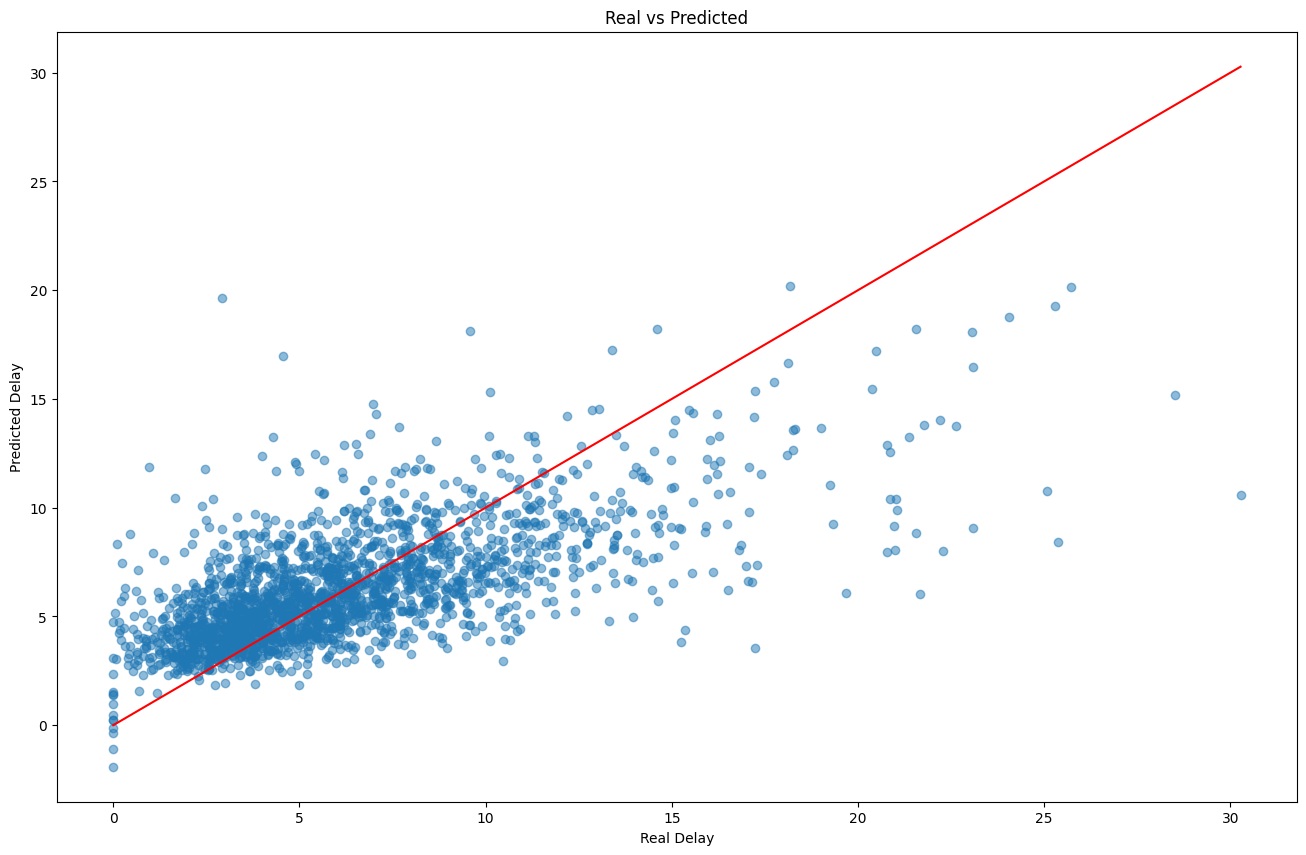

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error

df = pd.read_csv("cleaned_dataset.csv")

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["month"] = df["Date"].dt.month

target = "Retard moyen de tous les trains à l'arrivée"

features = [
    "month",
    "Durée moyenne du trajet",
    "Nombre de circulations prévues",
    "Service",
    "Gare de départ",
    "Gare d'arrivée"
]

X = df[features].copy()
y = df[target]

categorical_cols = X.select_dtypes(include="object").columns

X = pd.get_dummies(
    X,
    columns=categorical_cols,
    drop_first=False
)

X = X.replace([np.inf, -np.inf], np.nan)
X = X.dropna()
y = y.loc[X.index]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

model = HistGradientBoostingRegressor(
    max_iter=600,
    learning_rate=0.05,
    max_depth=6,
    min_samples_leaf=20,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Test R2:", r2_score(y_test, y_pred))
print("Test MAE:", mean_absolute_error(y_test, y_pred))

cv_scores = cross_val_score(
    model,
    X,
    y,
    cv=5,
    scoring="r2"
)

print("CV R2 mean:", cv_scores.mean())

plt.figure(figsize=(16,10))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel("Real Delay")
plt.ylabel("Predicted Delay")
plt.title("Real vs Predicted")
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red"
)
plt.show()

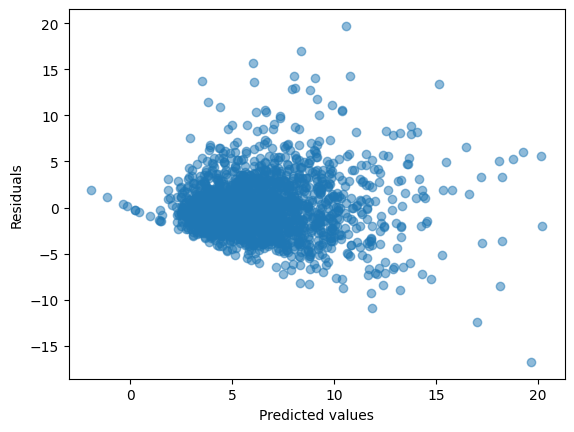

In [15]:

plt.scatter(y_pred, y_test - y_pred, alpha=0.5)
plt.xlabel("Predicted values")
plt.ylabel("Residuals")
plt.show()

This model uses only features available before departure
it is suitable for real world delay prediction+

R2: 0.9052475769792274
MAE: 0.8260157350134529


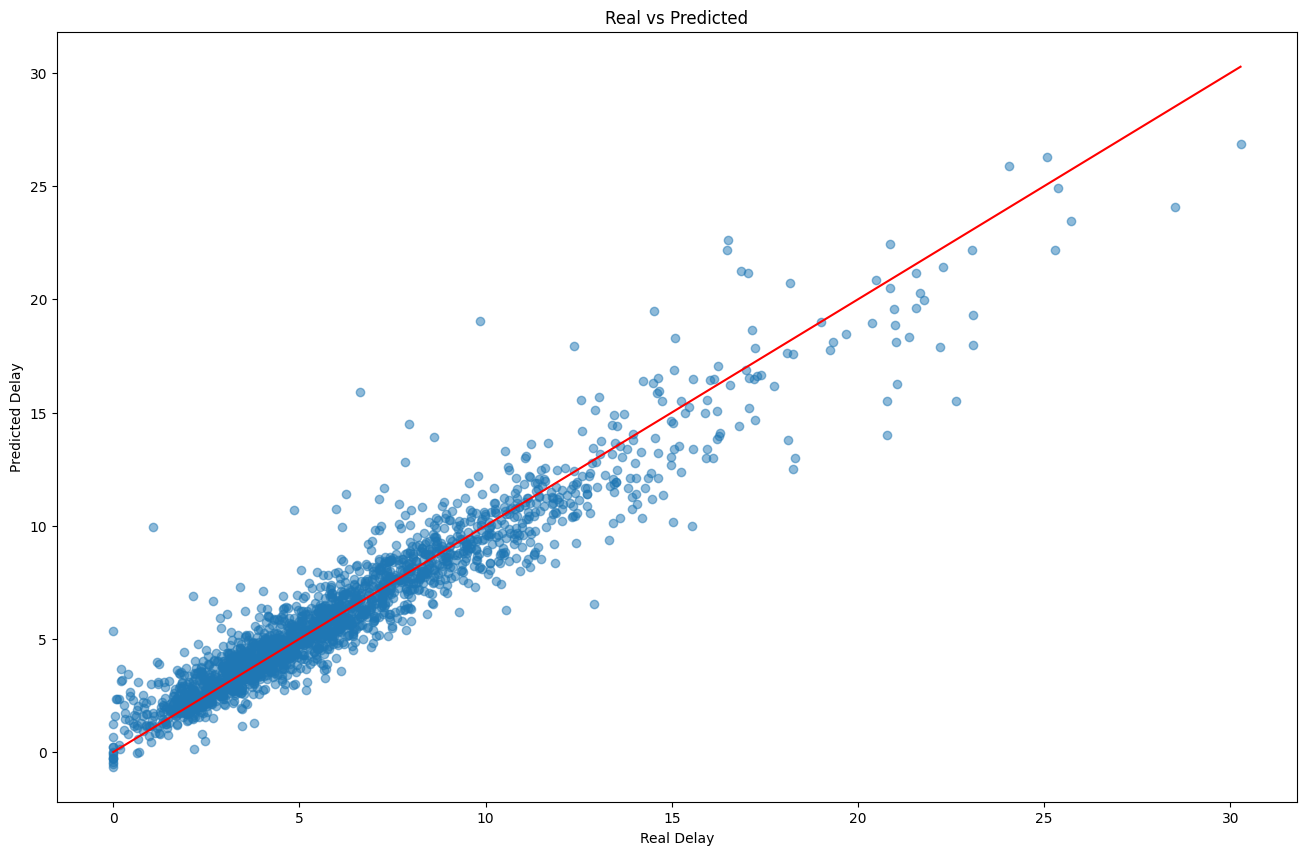

In [16]:
target = "Retard moyen de tous les trains à l'arrivée"

y = df[target]

X = df.drop(columns=[target, "Date"]).copy()

X = X.replace([float("inf"), -float("inf")], np.nan)
X = X.dropna()
y = y.loc[X.index]

categorical_cols = X.select_dtypes(include="object").columns

X = pd.get_dummies(
    X,
    columns=categorical_cols,
    drop_first=False
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = HistGradientBoostingRegressor(
    max_depth=6,
    learning_rate=0.05,
    max_iter=500,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("R2:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))

plt.figure(figsize=(16,10))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel("Real Delay")
plt.ylabel("Predicted Delay")
plt.title("Real vs Predicted")
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red"
)
plt.show()

